# Riesgo de ampliación del plazo en contratos públicos (SECOP II)

Modelo que, al firmar un contrato estatal, estima la probabilidad de que termine con el plazo ampliado (prórroga, suspensión o ajuste de fechas). Lo usan veedurías y oficinas de control interno para priorizar qué contratos vigilar.

**Fuente de datos:** Datos Abiertos Colombia (datos.gov.co), Agencia Nacional de Contratación Pública – Colombia Compra Eficiente. Licencia CC BY-SA 4.0. Conjuntos: Contratos Electrónicos (`jbjy-vk9h`), Procesos de Contratación (`p6dx-8zbt`) y Modificaciones a contratos (`u8cx-r425`).

Las secciones leen la base procesada v1 (`data/processed/v1_A/`) y los resultados de `src/modelado.py`, `src/evaluar_j3.py` y `src/evaluar_j3_extra.py` (`resultados/j3_*`). Con los flags `RECALCULAR = True` de 3.5 y 3.6 se vuelven a correr esas etapas (unos 12 y 9 minutos). Cada decisión sigue el formato **Decisión / Alternativas / Por qué / Evidencia**.

---

# 3.1 Definición del problema

El detalle completo está en `docs/01_definicion_problema.md`.

**Pregunta.** Al firmar un contrato, ¿qué tan probable es que termine con el plazo ampliado, después de lo pactado al firmar?

| Elemento | Definición |
|---|---|
| Tipo de tarea | Clasificación binaria supervisada; la salida es una probabilidad (puntaje de riesgo). |
| Unidad de predicción | Un contrato electrónico de SECOP II. |
| Momento de la predicción | La fecha de firma. Solo información disponible hasta ese momento. |
| Etiqueta | Ampliación del plazo: días adicionados > 0 **o** una modificación publicada que extendió el plazo más de un día después de la firma. |
| Horizonte | El desenlace ocurre meses después; solo se evalúan contratos maduros (plazo ya vencido). |

**Usuarios y decisión.** Veedurías ciudadanas y oficinas de control interno. Con recursos limitados, deciden **qué contratos vigilar primero**: el modelo los ordena por riesgo. Por eso importan la precisión en los primeros *k* contratos y el PR-AUC más que la exactitud global (sección 3.7).

**Qué ingresa el usuario** (enlaza con 3.8): el usuario solo pega el número del contrato. La app consulta Contratos y Procesos en datos.gov.co, construye **solo** las variables disponibles al firmar (las mismas del entrenamiento) e ignora las columnas de la lista de fuga, aunque la API las devuelva actualizadas.

| Lo que pega el usuario | Lo que consulta la app | Lo que construye | Lo que descarta y por qué |
|---|---|---|---|
| Número del contrato | Contratos (`jbjy-vk9h`) y Procesos (`p6dx-8zbt`) | Las 39 `FEATURES` de `src/features.py` (tipo, modalidad, calendario, precio base, duración planeada, competencia, entidad…) | `estado_contrato`, `fecha_de_fin_del_contrato`, `valor_del_contrato`, los 6 montos, pagos y saldos: son posteriores a la firma (`docs/LISTA_FUGA.md`). |

**Ética y alcance.** El modelo estima riesgo de ampliación del plazo, no detecta corrupción. Es una herramienta de priorización; la decisión de actuar siempre es de una persona.

---

# 3.2 Preprocesamiento


**Qué pide el enunciado:** limpieza, faltantes, atípicos, codificación y escalado, todo justificado.

**Cómo está repartido:** lo determinista y fila a fila (fechas, UNSPSC, logaritmos de los montos) está en `src/features.py` (Kevin). Todo lo que se **aprende de los datos** (cuantiles, medianas, codificación, escalado, *target encoding*) está en el `Pipeline` de `src/preprocesamiento.py`, que se ajusta solo con el train y se guarda dentro del modelo. Así no hay fuga y la app aplica exactamente la misma transformación.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":      # permite correrlo tambien desde notebooks/
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import config, evaluacion as E, features as F
RES = RAIZ / "resultados"
BASE_V1 = config.DATA_PROCESSED / "v1_A" / "base_contratos.parquet"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
from src import preprocesamiento as P

base = pd.read_parquet(BASE_V1)
X = F.construir_features(base)
idx_tr, idx_te = E.split_temporal(base, config.ANIO_TEST)
Xtr, ytr = X.loc[idx_tr], base.loc[idx_tr, "y"]
print(f"Base v1: {len(base):,} contratos | train 2019-2023 maduros: {len(idx_tr):,} | test 2024 maduros: {len(idx_te):,}")
print(f"{len(F.FEATURES)} features: {len(F.FEATURES_CAT)} categóricas y {len(F.FEATURES_NUM)} numéricas")

Base v1: 452,494 contratos | train 2019-2023 maduros: 261,249 | test 2024 maduros: 88,088
39 features: 21 categóricas y 18 numéricas


## Faltantes

Se miden en el train. Ninguna fila se borra: los bloques son pequeños y quitarlos sesgaría la muestra.

In [2]:
falt = (Xtr.isna().mean() * 100).round(2)
falt = falt[falt > 0].sort_values(ascending=False).rename("% faltante (train)")
tasa = pd.Series({c: ytr[Xtr[c].isna()].mean() for c in falt.index}, name="tasa de y con faltante")
display(pd.concat([falt, tasa], axis=1))
print(f"Tasa de y en el train: {ytr.mean():.3f}")

,% faltante (train),tasa de y con faltante
dias_firma_a_inicio,1.020,0.000
unspsc_segmento,0.720,0.285
unspsc_familia,0.720,0.285
fin_planeado_cruza_anio,0.110,0.113
p_dur_dias,0.110,0.113


Tasa de y en el train: 0.289


**Decisión:** en los modelos de árboles los faltantes quedan como `NaN` (el HGB los maneja de forma nativa y aprende hacia dónde mandarlos); en kNN y SVM se imputan con la mediana del train y se agrega una columna `<feature>_faltante`. En las categóricas, el faltante es su propia categoría (`SIN_DATO`) en el one-hot o un `NaN` en los códigos ordinales.
- **Alternativas:** borrar filas; imputar 0.
- **Por qué:** imputar 0 confundiría el faltante con "cero respuestas" o "sin lotes", que son valores reales. El indicador conserva la información de que el dato faltaba.
- **Evidencia:** tabla de arriba; todos los faltantes están por debajo del 1,1 % del train. Los contratos sin fecha de inicio no tienen ningún positivo en el train (tasa 0,000): el indicador de faltante es señal, no ruido. [VERIFICADO; causa NO EVALUADA]

## Atípicos: la duración planeada (`p_dur_dias`)

La v1 trae duraciones imposibles (una de 4.078 millones de días) y un 5,2 % de los contratos del train con duración 0.

Máximo en toda la base: 4,078,903,500 días
Duración 0 en el train: 5.2%  |  faltante: 0.11%
Cuantiles de las duraciones > 0 en el train: {0.5: 143.0, 0.9: 330.0, 0.99: 420.0, 0.999: 1259.0}
Tasa de y: duración 0 = 0.253 | duración > 0 = 0.291


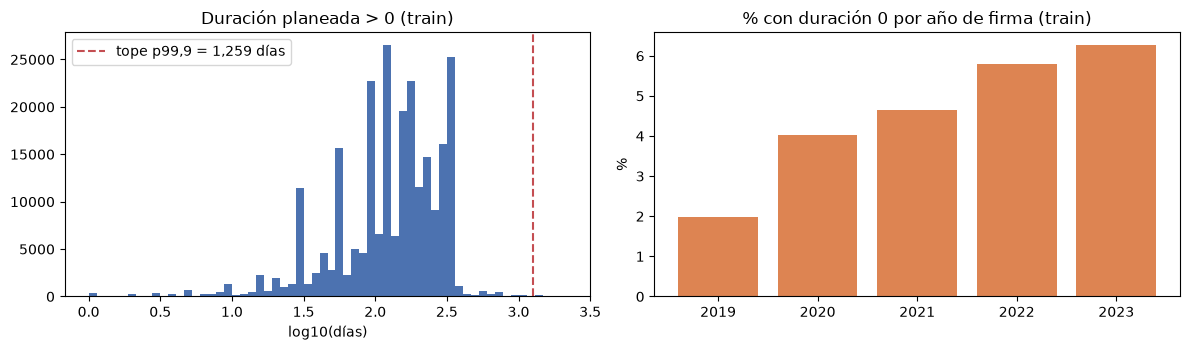

In [3]:
d = X.loc[idx_tr, "p_dur_dias"]
print(f"Máximo en toda la base: {X['p_dur_dias'].max():,.0f} días")
print(f"Duración 0 en el train: {(d == 0).mean():.1%}  |  faltante: {d.isna().mean():.2%}")
print("Cuantiles de las duraciones > 0 en el train:", d[d > 0].quantile([.5, .9, .99, .999]).round(0).to_dict())
y_tr = base.loc[idx_tr, "y"]
print(f"Tasa de y: duración 0 = {y_tr[d == 0].mean():.3f} | duración > 0 = {y_tr[d > 0].mean():.3f}")

prep = P.construir_preprocesador("arbol").fit(Xtr, ytr)
tope = prep.named_transformers_["dur"].tope_[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(np.log10(d[d > 0]), bins=60, color="#4C72B0")
ax[0].axvline(np.log10(tope), color="#C44E52", ls="--", label=f"tope p99,9 = {tope:,.0f} días")
ax[0].set_xlabel("log10(días)"); ax[0].set_title("Duración planeada > 0 (train)"); ax[0].legend()
t = base.loc[idx_tr].assign(cero=d.eq(0)).groupby("anio_firma")["cero"].mean() * 100
ax[1].bar(t.index, t.values, color="#DD8452"); ax[1].set_title("% con duración 0 por año de firma (train)"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

**Decisión:** `p_dur_dias = 0` pasa a faltante con el indicador `p_dur_dias_cero`, y las duraciones se recortan por arriba al percentil 99,9 del train.
- **Alternativas:** borrar los contratos; recortar a un tope fijo de 3.650 días (la sugerencia del EDA con la v0); dejar los valores crudos.
- **Por qué:** una duración 0 no es un contrato instantáneo, es un dato sin diligenciar, y se comporta distinto (en el train, tasa de y 0,253 frente a 0,291), así que el indicador le permite al modelo usar esa señal. El tope sale del train, así que es parte del `Pipeline` y no un número escrito a mano. Para el HGB el recorte casi no cambia nada (los árboles cortan por rangos), pero en kNN y SVM un valor de 4.078 millones dominaría la distancia.
- **Evidencia:** gráfica y cifras de arriba.

## Codificación y escalado: un preprocesador por familia de modelo

| | Árboles (HGB, árbol, RF) | Distancia (kNN, SVM) |
|---|---|---|
| Categóricas | códigos ordinales (200 más frecuentes; nuevas y faltantes → `NaN`) | one-hot; categorías con < 1 % del train agrupadas |
| `nit_entidad` (2.330 entidades) | `TargetEncoder` con validación cruzada interna | igual |
| Conteos de competencia | crudos | `log1p` + `RobustScaler` |
| Mes y día de la semana | crudos | seno y coseno |
| Otras numéricas | crudas | mediana + indicador + `RobustScaler` |
| Redundantes (Spearman ≥ 0,995) | se mantienen | se deja una de cada par |
| `p_proveedores_que_manifestaron` | se quita (constante 0) | se quita |

In [4]:
for fam in ("arbol", "distancia"):
    ct = P.construir_preprocesador(fam).fit(Xtr, ytr)
    Z = ct.transform(X.loc[idx_te])
    print(f"{fam:10s}: {Z.shape[1]:3d} columnas de salida | columnas con NaN en 2024: {int(Z.isna().any().sum())}")
te = prep.named_transformers_["entidad"]
print(f"TargetEncoder: {len(te.categories_[0]):,} entidades; las no vistas reciben la media del train ({te.target_mean_:.3f})")

arbol     :  39 columnas de salida | columnas con NaN en 2024: 18


distancia : 158 columnas de salida | columnas con NaN en 2024: 0
TargetEncoder: 2,330 entidades; las no vistas reciben la media del train (0.289)


**Decisión: `TargetEncoder` para la entidad.**
- **Alternativas:** one-hot (2.330 columnas, la mayoría con muy pocos contratos); códigos ordinales (un número arbitrario por entidad).
- **Por qué:** la entidad es la señal más fuerte (H6), pero con muchas categorías. El `TargetEncoder` la resume en la tasa histórica suavizada de la entidad. Dentro del train usa validación cruzada (cada fila se codifica con los otros pliegues), así que el modelo no ve su propia etiqueta; en la búsqueda se vuelve a ajustar en cada fold temporal.
- **Evidencia:** en el SHAP global de la sección 3.6, `nit_entidad` es la feature más importante.

**Decisión: códigos ordinales y no categorías nativas en el HGB.**
- **Alternativas:** categorías nativas del HGB.
- **Por qué:** con categorías nativas `TreeExplainer` da atribuciones incorrectas sin avisar (plan, sección 0 punto 7) y la app se niega a explicar. Con los mismos hiperparámetros las nativas solo ganan +0,003 de PR-AUC en los folds temporales (sección 3.5), menos que la variación entre folds.
- **Evidencia:** sección 3.5, tabla "nativas frente a códigos".

**Decisión: one-hot + escalado robusto solo para kNN y SVM.**
- **Por qué:** los árboles no dependen de la escala ni de transformaciones monótonas; las distancias sí. `RobustScaler` usa mediana y rango intercuartílico, así que los atípicos que quedan no dominan. Los meses son cíclicos: diciembre debe quedar cerca de enero.

## Sin fuga en el preprocesamiento

Lo aprendido (tope de duración, medianas, categorías, codificación de la entidad) depende solo de las filas con las que se ajusta. La prueba `tests/test_preprocesamiento.py::test_ajuste_solo_con_train` lo verifica: cambiar el test no mueve nada de lo aprendido.

In [5]:
otro = X.copy()
otro.loc[idx_te, "p_dur_dias"] = 99999.0
a = P.construir_preprocesador("arbol").fit(X.loc[idx_tr], ytr).named_transformers_["dur"].tope_
b = P.construir_preprocesador("arbol").fit(otro.loc[idx_tr], ytr).named_transformers_["dur"].tope_
print("El tope aprendido no cambia al alterar el test:", np.array_equal(a, b))

El tope aprendido no cambia al alterar el test: True


# 3.3 Análisis exploratorio (EDA)

El EDA profundo (gráficas y narrativa de H1-H7, etiqueta, censura, deriva y fuga) está en `00_exploracion/REPORTE_EXPLORACION.md` y la base v1. Aquí queda el marco que usa el modelado.

**Por qué los datos de la firma deberían predecir una ampliación del plazo** (hipótesis que guían el EDA y que la sección 3.6 contrasta con SHAP):

| Hipótesis | Señal observable al firmar |
|---|---|
| H1. Procesos apresurados | Tiempo entre la publicación del proceso y la firma |
| H2. Poca competencia | Número de oferentes o respuestas en el proceso |
| H3. La modalidad influye | Contratación directa frente a modalidades competitivas |
| H4. Anualidad presupuestal | Contratos firmados en el último trimestre del año |
| H5. Plazos subestimados | Duración planeada frente a la típica para ese objeto |
| H6. Hábitos de la entidad | Tasa histórica de ampliaciones de la entidad contratante |
| H7. Tipo de objeto | Obra, servicios, suministros (clasificación UNSPSC) |

**Etiqueta, censura y deriva** (detalle en `docs/01_definicion_problema.md` §2): la etiqueta `y` marca ampliación del plazo; los contratos aún en ejecución se excluyen por censura (solo maduros); la tasa de días adicionados salta en 2025 por un efecto de registro, no de comportamiento, y con `y` la tasa de 2025 queda dentro del rango de los demás años.

**Fuga.** La lista viva es `docs/LISTA_FUGA.md`. La sección 3.6 muestra el contraste "con fuga" (los 6 montos) para dimensionar cuánto inflan el resultado.

---

# 3.4 Paradigma y 3.5 Metodología y selección del modelo


**Paradigma (3.4):** aprendizaje supervisado, clasificación binaria. Al momento de la firma se estima la probabilidad de que el contrato termine con el plazo ampliado (`y`). Hay etiqueta histórica para 2019-2025 y la decisión del usuario es ordenar contratos para revisarlos, así que un modelo que puntúa y ordena es lo que se necesita.

**Metodología (3.5):**
- Split temporal: train 2019-2023, test 2024 y 2025 como deriva. Solo contratos maduros.
- Dentro del train, folds temporales de ventana creciente: se entrena con los años anteriores y se valida en 2021, 2022 y 2023.
- Cinco modelos del curso, con búsqueda aleatoria de hiperparámetros sobre esos folds y un tope de 15 minutos por modelo. kNN y SVM sobre una submuestra de 20.000 contratos.
- Métrica de selección: PR-AUC medio de los folds. El test 2024 no se usa para elegir.

In [6]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":      # permite correrlo tambien desde notebooks/
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import config, evaluacion as E, features as F
RES = RAIZ / "resultados"
BASE_V1 = config.DATA_PROCESSED / "v1_A" / "base_contratos.parquet"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
from src import modelado as MD, modelo as MO

RECALCULAR = False     # True vuelve a correr la busqueda (unos 12 min) y reescribe resultados/j3_busqueda_*
if RECALCULAR:
    import subprocess
    subprocess.run([sys.executable, "-m", "src.modelado"], cwd=RAIZ, check=True)
busq = json.loads((RES / "j3_busqueda_resumen.json").read_text(encoding="utf-8"))
j3 = json.loads((RES / "j3_resumen.json").read_text(encoding="utf-8"))

## Folds temporales

**Decisión:** validación con ventana creciente y no `KFold` aleatorio.
- **Por qué:** el modelo se va a usar con contratos futuros, y el SECOP II cambió mucho entre años (más contratación directa, más personas naturales). Un fold aleatorio mezclaría años y daría una estimación optimista.
- **Evidencia:** la tasa de positivos sube de 0,273 en el train del primer fold a 0,300 en la validación de 2023, y en el test 2024 baja a 0,247.

In [7]:
base = pd.read_parquet(BASE_V1, columns=["anio_firma", "y", "eval_madura", "nit_entidad", "eval_dur_planeada_dias"])
idx_tr, _ = E.split_temporal(base, config.ANIO_TEST)
an, y = base.loc[idx_tr, "anio_firma"].to_numpy(), base.loc[idx_tr, "y"].to_numpy()
pd.DataFrame([{"validación": int(an[v][0]), "años de train": f"{an[t].min()}-{an[t].max()}", "n train": len(t),
               "tasa train": y[t].mean(), "n validación": len(v), "tasa validación": y[v].mean()}
              for t, v in E.folds_temporales(an)])

,validación,años de train,n train,tasa train,n validación,tasa validación
0,2021,2019-2020,50482,0.273,56370,0.278
1,2022,2019-2021,106852,0.276,70899,0.295
2,2023,2019-2022,177751,0.283,83498,0.300


## Las reglas simples que hay que superar

- **Tasa base:** el mismo puntaje para todos.
- **Tasa histórica por entidad:** (positivos + m · p0) / (contratos + m); las entidades nuevas reciben p0. El suavizado `m` se elige con los mismos folds temporales: entre los `m` a menos de 0,005 del mejor ROC-AUC, gana el de mejor precisión en el top-k. Con m = 0 el top 1 % se llena de entidades con 1 de 1 positivos.

In [8]:
tm = pd.read_csv(RES / "j1_v1_elegir_m.csv")
display(tm.style.format(precision=4).apply(lambda r: ["background-color: #dbe9f6" if r["elegida"] else "" for _ in r], axis=1))

,m,roc_auc,pr_auc,p@1%,p@5%,p@10%,p_topk_media,elegida
0,0,0.6642,0.4838,0.7366,0.7310,0.6115,0.6931,False
1,1,0.6637,0.4868,0.7769,0.7375,0.6153,0.7099,False
2,2,0.6631,0.4877,0.7798,0.7536,0.6159,0.7164,False
3,5,0.6617,0.4885,0.7798,0.7608,0.6307,0.7238,False
4,10,0.6604,0.4883,0.7798,0.7643,0.6340,0.7260,True
5,20,0.6589,0.4882,0.7798,0.7658,0.6403,0.7287,False
6,50,0.6558,0.4873,0.7798,0.7675,0.6425,0.7299,False
7,100,0.6531,0.4862,0.7798,0.7701,0.6475,0.7325,False


## Búsqueda de hiperparámetros

,n_train,n_iter,segundos,pr_auc_cv,pr_auc_cv_std,roc_auc_cv
rf,"261,249",12,300,0.5781,0.0130,0.7567
hgb,"261,249",25,287,0.5765,0.0046,0.7620
arbol,"261,249",30,51,0.5318,0.0104,0.7321
svm,"20,000",10,45,0.5225,0.0407,0.6904
knn,"20,000",15,17,0.5169,0.0471,0.6925


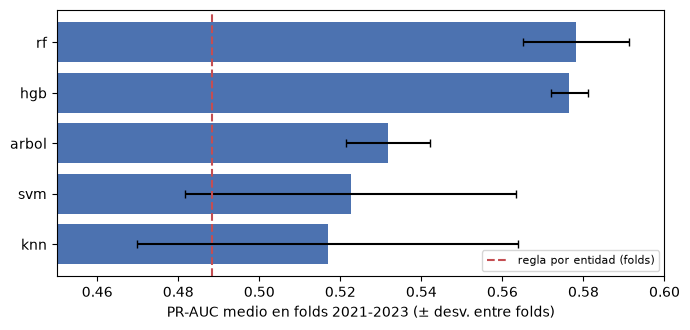

hgb    {'l2_regularization': 0.002259279742015696, 'learning_rate': 0.034003508264422166, 'max_features': 0.5, 'max_iter': 200, 'max_leaf_nodes': 127, 'min_samples_leaf': 20}
arbol  {'min_samples_leaf': 200, 'max_depth': 12, 'criterion': 'entropy', 'class_weight': None}
rf     {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': None}
knn    {'weights': 'distance', 'p': 1, 'n_neighbors': 100}
svm    {'C': 1.5751320499779735, 'gamma': 0.01}


In [9]:
t = pd.DataFrame(busq).T[["n_train", "n_iter", "segundos", "pr_auc_cv", "pr_auc_cv_std", "roc_auc_cv"]].astype(float)
t = t.sort_values("pr_auc_cv", ascending=False)
display(t.style.format({"n_train": "{:,.0f}", "n_iter": "{:.0f}", "segundos": "{:.0f}", "pr_auc_cv": "{:.4f}",
                        "pr_auc_cv_std": "{:.4f}", "roc_auc_cv": "{:.4f}"}))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(t.index[::-1], t["pr_auc_cv"][::-1], xerr=t["pr_auc_cv_std"][::-1], color="#4C72B0", capsize=3)
ax.axvline(tm.loc[tm["elegida"], "pr_auc"].iloc[0], color="#C44E52", ls="--", label="regla por entidad (folds)")
ax.set_xlim(0.45, 0.6); ax.set_xlabel("PR-AUC medio en folds 2021-2023 (± desv. entre folds)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for k, v in busq.items():
    print(f"{k:6s} {v['mejores_parametros']}")

**Interpretación:** los dos ensambles de árboles (HGB y RF) quedan arriba y prácticamente empatados (0,5765 y 0,5781). El árbol solo, kNN y SVM quedan claramente por debajo; kNN y SVM además se entrenaron con 20.000 contratos y varían mucho entre folds. Todas las búsquedas terminaron dentro del tope de 15 minutos.

**Decisión: el modelo final es el HGB.**
- **Alternativas:** Random Forest, que tiene un PR-AUC medio un poco mayor.
- **Por qué:** la diferencia (0,0016) es menor que la desviación entre folds del RF (0,013), así que están empatados. El HGB es más estable entre folds (desviación de 0,0046), pesa unos 3 MB y tiene `decision_function`, que la app usa para verificar que los valores SHAP suman la salida del modelo.
- **Evidencia:** tabla y gráfica de arriba. Early stopping desactivado (regla 4).

## Categorías nativas frente a códigos ordinales (HGB, mismos hiperparámetros)

In [10]:
nat = pd.DataFrame({k: {"PR-AUC cv": v["pr_auc_cv"], "ROC-AUC cv": v["roc_auc_cv"], "PR-AUC por fold (2021, 2022, 2023)": v["pr_auc_por_fold"]}
                    for k, v in j3["nativas_vs_ordinal"].items()}).T
display(nat)

,PR-AUC cv,ROC-AUC cv,"PR-AUC por fold (2021, 2022, 2023)"
ordinal,0.576,0.762,"[0.5809, 0.5783, 0.5702]"
nativas,0.580,0.765,"[0.586, 0.5772, 0.5762]"


**Decisión:** códigos ordinales (opción b del plan).
- **Por qué:** las nativas ganan +0,003 de PR-AUC medio y no en todos los folds (pierden en 2022); con ellas SHAP no es confiable y la app no explicaría. Se gana explicabilidad exacta a cambio de una diferencia que está dentro del ruido.
- **Evidencia:** tabla de arriba; error de aditividad de SHAP de 7e-13 con los códigos (sección 3.6).

## El modelo final

`src/modelo.py: construir_pipeline()` devuelve el `Pipeline` del modelo v1 sin ajustar (lo usa también el monitoreo de la sección 3.9). Se entrena con 2019-2023 y se guarda en `models/modelo_prorroga_v1.joblib` con su `.json`.

In [11]:
from src import modelo_io
pipe, meta = modelo_io.cargar_modelo(config.MODELS / "modelo_prorroga_v1.joblib")
print(meta["version"], "|", meta["modelo"]["clase"], "| categorías nativas:", meta["modelo"]["categorias_nativas"])
print("Hiperparámetros:", meta["modelo"]["hiperparametros"])
print("Train:", meta["datos"]["anios_train"], f"{meta['datos']['n_train']:,} contratos, tasa {meta['datos']['tasa_base_train']}")
pipe

v1.0 | HistGradientBoostingClassifier | categorías nativas: False
Hiperparámetros: {'early_stopping': False, 'l2_regularization': 0.002259279742015696, 'learning_rate': 0.034003508264422166, 'max_features': 0.5, 'max_iter': 200, 'max_leaf_nodes': 127, 'min_samples_leaf': 20}
Train: [2019, 2023] 261,249 contratos, tasa 0.2887


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](39,)","['tipo_de_contrato','modalidad_de_contratacion', 'justificacion_modalidad_de',...,'p_respuestas_externas', 'p_conteo_de_respuestas_a_ofertas','p_proveedores_unicos_con']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,39
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('dur', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature nam

# 3.6 Generalización


**Qué pide el enunciado:** mostrar que el modelo funciona con datos que no vio, sin sobreajuste ni fuga.

**Cómo:** test 2024 (los hiperparámetros ya estaban elegidos con los folds), deriva 2025, entidades que no estaban en el train, ablación de las features con riesgo de fuga y SHAP global enlazado a las hipótesis H1-H7. Los intervalos son IC 95 % con bootstrap **por entidad** (200 repeticiones): los contratos de una misma entidad están correlacionados y remuestrear contratos daría intervalos demasiado estrechos.

> Nota honesta: durante el desarrollo de J1 y J2 se miró 2024 como control de cordura (reproducir las cifras de la F0 y probar el `Pipeline`). Ninguna elección de hiperparámetros, features o modelo se hizo con esas cifras.

In [12]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":      # permite correrlo tambien desde notebooks/
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import config, evaluacion as E, features as F
RES = RAIZ / "resultados"
BASE_V1 = config.DATA_PROCESSED / "v1_A" / "base_contratos.parquet"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RECALCULAR = False     # True vuelve a correr la evaluacion completa (unos 9 min) y reescribe resultados/j3_*
if RECALCULAR:
    import subprocess
    subprocess.run([sys.executable, "-m", "src.evaluar_j3"], cwd=RAIZ, check=True)
j3 = json.loads((RES / "j3_resumen.json").read_text(encoding="utf-8"))
modelos = pd.read_csv(RES / "j3_test2024_modelos.csv")

def tabla(t, metricas, nombres=None):
    t = t[t["metrica"].isin(metricas)].copy()
    t["valor [IC]"] = [f"{a:.3f} [{b:.3f}, {c:.3f}]" for a, b, c in zip(t["valor"], t["ic_inf"], t["ic_sup"])]
    t["dif. vs regla [IC]"] = [f"{a:+.3f} [{b:+.3f}, {c:+.3f}]" for a, b, c in zip(t["dif"], t["dif_ic_inf"], t["dif_ic_sup"])]
    out = t.pivot(index="modelo", columns="metrica", values=["valor [IC]", "dif. vs regla [IC]"])
    return out.reindex(nombres) if nombres else out

## Test 2024

In [13]:
orden = ["regla_base", "regla_entidad", "hgb", "rf", "arbol", "svm", "knn"]
display(tabla(modelos, ["pr_auc", "roc_auc"], orden))
print("Criterio de aceptación (IC de la diferencia de PR-AUC contra la regla excluye 0):", j3["criterio_aceptacion_final"])

valor [IC]                        \
metrica                      pr_auc               roc_auc   
modelo                                                      
regla_base     0.247 [0.215, 0.285]  0.500 [0.500, 0.500]   
regla_entidad  0.470 [0.355, 0.562]  0.682 [0.628, 0.726]   
hgb            0.584 [0.488, 0.659]  0.781 [0.752, 0.807]   
rf             0.580 [0.481, 0.657]  0.779 [0.748, 0.806]   
arbol          0.537 [0.441, 0.616]  0.751 [0.721, 0.782]   
svm            0.523 [0.404, 0.613]  0.730 [0.689, 0.766]   
knn            0.509 [0.392, 0.604]  0.719 [0.678, 0.754]   

                    dif. vs regla [IC]                           
metrica                         pr_auc                  roc_auc  
modelo                                                           
regla_base     -0.223 [-0.292, -0.129]  -0.182 [-0.226, -0.128]  
regla_entidad  +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]  
hgb            +0.114 [+0.082, +0.158]  +0.099 [+0.067, +0.130]  
rf             +0.110 [+0.081, +0.148]  +0.097 [+0.067, +0.125]  
arbol          +0.067 [+0.036, +0.113]  +0.070 [+0.039, +0.100]  
svm            +0.053 [+0.030, +0.085]  +0.048 [+0.033, +0.070]  
knn            +0.039 [+0.015, +0.065]  +0.037 [+0.014, +0.060]

Criterio de aceptación (IC de la diferencia de PR-AUC contra la regla excluye 0): True


**Interpretación:** el HGB llega a 0,584 de PR-AUC frente a 0,470 de la regla por entidad (+0,114, IC [+0,082; +0,158]) y 0,247 de la tasa base, así que cumple el criterio de aceptación del plan. Las cifras de 2024 son parecidas a las de los folds (0,577), señal de que la búsqueda no sobreajustó la validación. Los cinco modelos le ganan a la regla, pero solo los ensambles lo hacen por un margen amplio.

## Deriva 2025

- (i) El **mismo modelo** entrenado con 2019-2023, evaluado en 2025.
- (ii) El modelo **reentrenado** con 2019-2024, evaluado en 2025.

In [14]:
der = pd.read_csv(RES / "j3_deriva_2025.csv")
print(f"2025: {j3['deriva_2025']['n']:,} contratos maduros, tasa base {j3['deriva_2025']['tasa_base']:.3f}")
display(tabla(der, ["pr_auc", "roc_auc"], ["regla_base", "regla_entidad", "final_2019_2023", "regla_entidad_2019_2024", "final_2019_2024"]))

2025: 99,702 contratos maduros, tasa base 0.271


valor [IC]                        \
metrica                                pr_auc               roc_auc   
modelo                                                                
regla_base               0.271 [0.243, 0.305]  0.500 [0.500, 0.500]   
regla_entidad            0.465 [0.385, 0.540]  0.656 [0.624, 0.691]   
final_2019_2023          0.550 [0.472, 0.642]  0.773 [0.747, 0.797]   
regla_entidad_2019_2024  0.467 [0.380, 0.543]  0.664 [0.629, 0.698]   
final_2019_2024          0.550 [0.469, 0.664]  0.785 [0.759, 0.811]   

                              dif. vs regla [IC]                           
metrica                                   pr_auc                  roc_auc  
modelo                                                                     
regla_base               -0.194 [-0.253, -0.131]  -0.156 [-0.191, -0.124]  
regla_entidad            +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]  
final_2019_2023          +0.084 [+0.033, +0.157]  +0.116 [+0.090, +0.143]  
regla_entidad_2019_2024  +0.002 [-0.006, +0.008]  +0.008 [-0.000, +0.015]  
final_2019_2024          +0.085 [+0.029, +0.173]  +0.129 [+0.103, +0.156]

**Interpretación:** en 2025 el modelo congelado baja de 0,584 a 0,550 de PR-AUC, pero le sigue ganando a la regla (+0,084, IC [+0,033; +0,157]) y el ROC-AUC casi no cambia (0,781 → 0,773). Reentrenar con 2024 no mejora el PR-AUC (0,550 en los dos casos), aunque sube un poco el ROC-AUC. Por eso el artefacto v1 se queda con 2019-2023 y el reentrenamiento se decide con la regla campeón-retador de la sección 3.9.

Recordatorio: `y_dias` salta a 20 % en 2025 por cómo se registra `dias_adicionados`, no por un cambio de comportamiento; con la etiqueta aprobada `y` la tasa de 2025 (0,271) está dentro del rango de los otros años.

## Entidades no vistas en el train

La regla por entidad no sabe nada de una entidad nueva (le da a todos sus contratos la tasa base). El modelo sí puede usar el resto de variables.

In [15]:
nv = j3["no_vistas"]
print(f"Contratos de 2024 de entidades no vistas: {nv['n']:,} ({nv['positivos']} positivos)")
for m in ("pr_auc", "roc_auc"):
    f = nv["final"][m]
    print(f"  {m}: {f['valor']:.3f} [{f['ic_inf']:.3f}, {f['ic_sup']:.3f}] | dif. vs regla {f['dif']:+.3f} [{f['dif_ic_inf']:+.3f}, {f['dif_ic_sup']:+.3f}]")
g = pd.read_csv(RES / "j3_por_grupo_2024.csv")
display(g[g["tipo"] == "entidad"][["modelo", "grupo", "n", "tasa_base", "pr_auc", "roc_auc"]])

Contratos de 2024 de entidades no vistas: 1,834 (211 positivos)
  pr_auc: 0.279 [0.170, 0.449] | dif. vs regla +0.164 [+0.069, +0.307]
  roc_auc: 0.721 [0.655, 0.791] | dif. vs regla +0.221 [+0.155, +0.291]


,modelo,grupo,n,tasa_base,pr_auc,roc_auc
0,final,no vista,1834,0.115,0.279,0.721
1,final,vista,86254,0.250,0.587,0.781
7,regla_entidad,no vista,1834,0.115,0.115,0.500
8,regla_entidad,vista,86254,0.250,0.474,0.685


**Interpretación:** en las entidades nuevas el modelo tiene ROC-AUC 0,721 y le gana a la regla por +0,221 (IC [+0,155; +0,291]). Es la parte más clara del aporte del modelo: sirve justo donde no hay historia. Son solo 211 positivos, por eso el intervalo del PR-AUC es ancho.

## Ablación: ¿la ventaja depende de las features con riesgo de fuga?

- `FEATURES_ABLACION_J3` = `dias_firma_a_inicio` y `fin_planeado_cruza_anio` (usan la fecha de inicio, "segura con limitación" en `docs/LISTA_FUGA.md`). Es la ablación obligatoria.
- `FEATURES_POR_VERIFICAR` = las 8 que se asumen fijas tras la firma pero no están comprobadas.

In [16]:
print("Ablación obligatoria:", F.FEATURES_ABLACION_J3)
print(f"Por verificar ({len(F.FEATURES_POR_VERIFICAR)}):", F.FEATURES_POR_VERIFICAR)
abl = pd.read_csv(RES / "j3_ablacion_2024.csv")
display(tabla(abl, ["pr_auc", "roc_auc_intra_pares"], ["regla_entidad", "final", "sin_ablacion_j3", "sin_por_verificar"]))

# el_contrato_puede_ser_prorrogado (excluida de FEATURES): efecto de AGREGARLA al HGB final
ext = json.loads((RES / "j3_extra_resumen.json").read_text(encoding="utf-8"))["prorrogable"]
prr = pd.read_csv(RES / "j3_extra_prorrogable_2024.csv")
display(tabla(prr, ["pr_auc", "roc_auc_intra_pares"], ["regla_entidad", "final", "final_mas_prorrogable"]))
print(f"Delta al agregar el_contrato_puede_ser_prorrogado: "
      f"PR-AUC {ext['delta_pr_auc_por_agregar_prorrogable']:+.4f}, "
      f"ROC-AUC {ext['delta_roc_auc_por_agregar_prorrogable']:+.4f}, "
      f"ROC-AUC intra {ext['delta_roc_auc_intra_pares_por_agregar_prorrogable']:+.4f}")

Ablación obligatoria: ['dias_firma_a_inicio', 'fin_planeado_cruza_anio']
Por verificar (8): ['log_pago_adelantado', 'p_proveedores_invitados', 'p_proveedores_con_invitacion', 'p_proveedores_que_manifestaron', 'p_respuestas_al_procedimiento', 'p_respuestas_externas', 'p_conteo_de_respuestas_a_ofertas', 'p_proveedores_unicos_con']


valor [IC]                        \
metrica                          pr_auc   roc_auc_intra_pares   
modelo                                                          
regla_entidad      0.470 [0.355, 0.562]  0.500 [0.500, 0.500]   
final              0.584 [0.488, 0.659]  0.701 [0.597, 0.757]   
sin_ablacion_j3    0.580 [0.488, 0.655]  0.698 [0.597, 0.754]   
sin_por_verificar  0.584 [0.489, 0.661]  0.701 [0.597, 0.757]   

                        dif. vs regla [IC]                           
metrica                             pr_auc      roc_auc_intra_pares  
modelo                                                               
regla_entidad      +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]  
final              +0.114 [+0.082, +0.158]  +0.201 [+0.097, +0.257]  
sin_ablacion_j3    +0.110 [+0.079, +0.153]  +0.198 [+0.097, +0.254]  
sin_por_verificar  +0.114 [+0.083, +0.157]  +0.201 [+0.097, +0.257]

valor [IC]                        \
metrica                              pr_auc   roc_auc_intra_pares   
modelo                                                              
regla_entidad          0.470 [0.355, 0.562]  0.500 [0.500, 0.500]   
final                  0.584 [0.488, 0.659]  0.701 [0.597, 0.757]   
final_mas_prorrogable  0.583 [0.487, 0.658]  0.702 [0.600, 0.757]   

                            dif. vs regla [IC]                           
metrica                                 pr_auc      roc_auc_intra_pares  
modelo                                                                   
regla_entidad          +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]  
final                  +0.114 [+0.082, +0.158]  +0.201 [+0.097, +0.257]  
final_mas_prorrogable  +0.113 [+0.083, +0.155]  +0.202 [+0.100, +0.257]

Delta al agregar el_contrato_puede_ser_prorrogado: PR-AUC -0.0010, ROC-AUC +0.0005, ROC-AUC intra +0.0006


**Interpretación:** sin las dos features de la fecha de inicio la ventaja sobre la regla casi no cambia (PR-AUC de +0,114 a +0,110; ROC-AUC dentro de entidad de +0,201 a +0,198) y los intervalos siguen lejos de 0. Quitar las 8 por verificar tampoco cambia nada. **La conclusión no depende de las variables con riesgo de fuga.**

`el_contrato_puede_ser_prorrogado` (excluida de `FEATURES` por ser sospechosa de editarse tras la firma, sección 0 punto 10 del plan): **agregarla** al HGB final mueve el PR-AUC 2024 en −0,0010 y el ROC-AUC en +0,0005, dentro del ruido entre folds. Confirma la decisión de dejarla fuera: no aporta señal útil y sí riesgo de fuga. [VERIFICADO: `src/evaluar_j3_extra.py`]

**Decisión:** se mantienen las 39 `FEATURES` y `el_contrato_puede_ser_prorrogado` queda fuera.
- **Alternativas:** quitar las dos de la ablación o las 8 por verificar por precaución; o incluir `el_contrato_puede_ser_prorrogado`.
- **Por qué:** ninguna de esas variantes cambia la conclusión; la limitación de la fecha de inicio (no ve cambios anteriores a la primera modificación) se cita como limitación.
- **Evidencia:** las dos tablas de arriba.

## Contraste "con fuga": los 6 montos de fuentes de recursos

El enunciado pide mostrar que el modelo no tiene fuga. Para dimensionar cuánto *inflaría* el resultado una fuga, se mide cuánto sube el HGB si se le meten los **6 montos por fuente de recursos** (`presupuesto_general_de_la_nacion_pgn`, `sistema_general_de_participaciones`, `sistema_general_de_regal_as`, recursos propios de alcaldías/gobernaciones, `recursos_de_credito`, `recursos_propios`). Son **fuga confirmada**: su suma es igual a `valor_del_contrato` en el 80,6 % de los contratos, y ese valor ya incluye las adiciones (`docs/LISTA_FUGA.md`, 'Solo EDA').

In [17]:
fuga = json.loads((RES / "j3_extra_fuga_montos.json").read_text(encoding="utf-8"))
i = fuga["fuente_datos_fuga"]
print(f"Fuga leída de {i['ruta']}: {i['archivos']} archivos, {i['filas_leidas']:,} filas, "
      f"{i['filas_duplicadas_eliminadas']} duplicados por id_contrato eliminados "
      f"({i['ids_duplicados']} ids, copias exactas) y {i['sin_match_en_crudo']} contratos de v1 sin match.")
print("La unión vive solo en memoria: no se guarda en la base ni entra en FEATURES.")
print(f"Train {fuga['n_train']:,} contratos, test {fuga['n_test']:,} (tasa base {fuga['tasa_base_test']:.3f}); "
      f"regla por entidad con m = {fuga['m_regla']:g}.")

t = fuga["tabla"]
variantes = ["final_limpio", "final_con_6_montos", "final_con_fuga_evidente"]
nombres = ["HGB limpio (v1)", "+ 6 montos", "+ fuga evidente"]
filas = []
for k in variantes:
    r = t[k]
    filas.append({
        "ROC-AUC [IC 95 %]": f"{r['roc_auc']['valor']:.3f} [{r['roc_auc']['ic_inf']:.3f}; {r['roc_auc']['ic_sup']:.3f}]",
        "PR-AUC [IC 95 %]": f"{r['pr_auc']['valor']:.3f} [{r['pr_auc']['ic_inf']:.3f}; {r['pr_auc']['ic_sup']:.3f}]",
    })
display(pd.DataFrame(filas, index=nombres))
s = fuga["subida_al_agregar_montos"]
e = fuga["subida_al_agregar_fuga_evidente"]
print(f"Al agregar los 6 montos: ROC-AUC {s['roc_auc']:+.3f}, PR-AUC {s['pr_auc']:+.3f}")
print(f"Al agregar fuga evidente: ROC-AUC {e['roc_auc']:+.3f}, PR-AUC {e['pr_auc']:+.3f}")

Fuga leída de data/raw/f2/contratos: 84 archivos, 452,515 filas, 21 duplicados por id_contrato eliminados (21 ids, copias exactas) y 0 contratos de v1 sin match.
La unión vive solo en memoria: no se guarda en la base ni entra en FEATURES.
Train 261,249 contratos, test 88,088 (tasa base 0.247); regla por entidad con m = 10.


,ROC-AUC [IC 95 %],PR-AUC [IC 95 %]
HGB limpio (v1),0.781 [0.752; 0.807],0.584 [0.488; 0.659]
+ 6 montos,0.917 [0.901; 0.929],0.851 [0.810; 0.884]
+ fuga evidente,0.984 [0.980; 0.988],0.967 [0.957; 0.976]


Al agregar los 6 montos: ROC-AUC +0.136, PR-AUC +0.267
Al agregar fuga evidente: ROC-AUC +0.204, PR-AUC +0.383


**Interpretación:** en la base v1, al meterle los 6 montos al HGB limpio el ROC-AUC sube de 0,781 a 0,917 (+0,136) y el PR-AUC de 0,584 a 0,851 (+0,267). La fuga evidente (estado_contrato one-hot, log1p de valor_del_contrato y días de firma a fin) lleva el ROC-AUC a 0,984 y el PR-AUC a 0,967. Junto con el precio base, los montos delatan las adiciones de valor, que son exactamente lo que no se puede conocer al firmar. **Por eso los 6 montos quedan fuera de `FEATURES` y el modelo limpio reporta las cifras de 3.6.**

> Contraste medido sobre la base v1_A (train 2019-2023, test 2024, IC 95 % por bootstrap de entidad) con el crudo de Contratos (`data/raw/f2/contratos`), unido solo para este contraste. Referencia histórica de la F0 (base v0, y_dias): ROC-AUC 0,751 → 0,807 y PR-AUC 0,333 → 0,429; ese 0,807/0,429 se parecía a la variante C de la exploración (0,809/0,436), inflada por lo mismo. [VERIFICADO: `src/evaluar_j3_extra.py`; `resultados/j3_extra_resumen.md`]

## SHAP global y las hipótesis H1-H7

`TreeExplainer` sobre el HGB con 3.000 contratos de 2024. Las columnas transformadas se suman por feature original.

Error de aditividad máximo: 7.4e-13 (la suma de SHAP reproduce la salida del modelo)


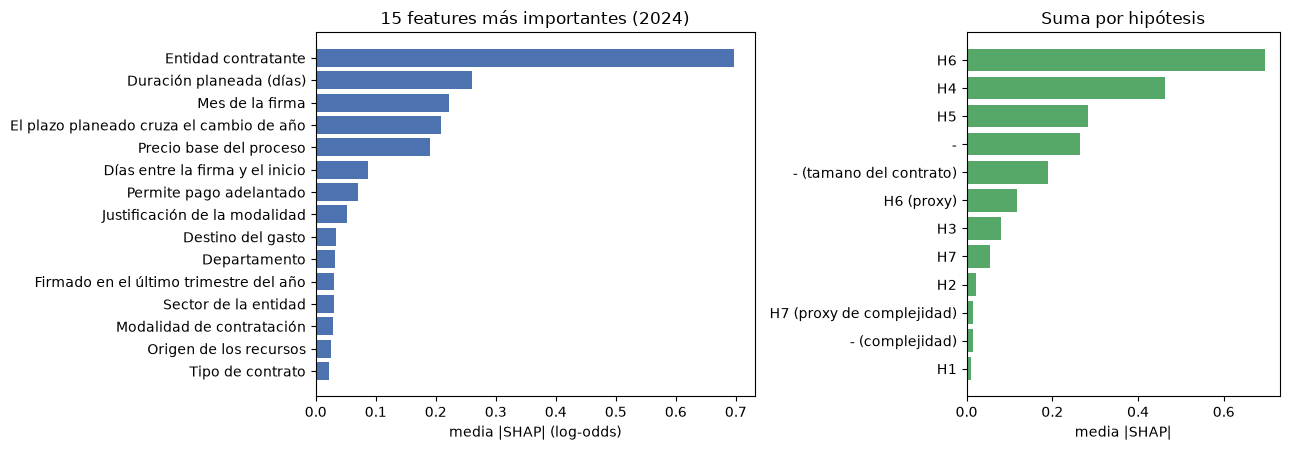

In [18]:
sh = pd.read_csv(RES / "j3_shap_global_2024.csv", index_col=0)
print(f"Error de aditividad máximo: {j3['shap']['error_aditividad_max']:.1e} (la suma de SHAP reproduce la salida del modelo)")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
top = sh.head(15)[::-1]
ax[0].barh([F.NOMBRES_LEGIBLES[f] for f in top.index], top["media_abs_shap"], color="#4C72B0")
ax[0].set_xlabel("media |SHAP| (log-odds)"); ax[0].set_title("15 features más importantes (2024)")
h = sh.groupby("hipotesis")["media_abs_shap"].sum().sort_values()
ax[1].barh(h.index, h.values, color="#55A868"); ax[1].set_title("Suma por hipótesis"); ax[1].set_xlabel("media |SHAP|")
plt.tight_layout(); plt.show()

**Interpretación:**
- **H6 (historia de la entidad)** es la señal dominante: `nit_entidad`, vía el `TargetEncoder`, suma más que cualquier otro grupo. Es coherente con que la regla por entidad sola ya llegue a 0,470 de PR-AUC.
- **H4 (calendario)**: el mes de la firma y si el fin planeado cruza el año son la segunda familia. Coincide con el EDA: enero 34 % de positivos frente a noviembre 16 %.
- **H5 (duración planeada)** y el **tamaño del contrato** (precio base) vienen después.
- **H2 (competencia)** y **H1 (tiempo entre publicación y firma)** aportan muy poco; la ablación de las 8 por verificar (casi todas de H2) lo confirma.
- Una advertencia: SHAP muestra en qué se apoya el modelo, no causalidad.

# 3.7 Métricas


**Para qué se usa el modelo:** una veeduría u oficina de control interno no puede revisar todos los contratos; revisa una lista corta. Lo que importa es **ordenar bien** y que los primeros de la lista sean de verdad contratos que terminan prorrogados.

| Métrica | Por qué |
|---|---|
| **PR-AUC** (principal) | resume la precisión en todos los cortes de la lista; con 25 % de positivos el ROC-AUC puede verse bien aunque los primeros puestos estén llenos de falsos positivos |
| **Precisión y recall en el top 1, 5 y 10 %** | es la decisión real: "si reviso el 5 % de mayor riesgo, ¿qué fracción estaba bien elegida y qué fracción de las prórrogas capturé?" |
| **ROC-AUC** | capacidad de ordenar, independiente de la tasa base; sirve para comparar años con tasas distintas |
| **ROC-AUC dentro de entidad** | lo que ve quien vigila una sola entidad: la regla por entidad da 0,5 ahí por construcción |
| **Tasa base** | siempre al lado: un PR-AUC de 0,58 solo se entiende frente a 0,25 |

No se usan exactitud ni F1 con un umbral fijo: el modelo entrega un orden, y la probabilidad cruda queda descalibrada cuando cambia la tasa (train 0,289, test 2024 0,247).

In [19]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":      # permite correrlo tambien desde notebooks/
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import config, evaluacion as E, features as F
RES = RAIZ / "resultados"
BASE_V1 = config.DATA_PROCESSED / "v1_A" / "base_contratos.parquet"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
from sklearn.metrics import precision_recall_curve
from src import modelo_io

base = pd.read_parquet(BASE_V1)
X = F.construir_features(base)
idx_tr, idx_te = E.split_temporal(base, config.ANIO_TEST)
pipe, meta = modelo_io.cargar_modelo(config.MODELS / "modelo_prorroga_v1.joblib")
y_te = base.loc[idx_te, "y"].to_numpy()
ent_tr, ent_te = base.loc[idx_tr, "nit_entidad"], base.loc[idx_te, "nit_entidad"]
m = json.loads((RES / "j3_resumen.json").read_text(encoding="utf-8"))["m_regla"]
s = {"modelo v1": pipe.predict_proba(X.loc[idx_te])[:, 1],
     "regla por entidad": E.regla_tasa_entidad(ent_tr, base.loc[idx_tr, "y"], ent_te, m)}
print(f"Test 2024: {len(y_te):,} contratos, tasa base {y_te.mean():.3f}")

Test 2024: 88,088 contratos, tasa base 0.247


## Curva precisión-recall y precisión en los primeros k

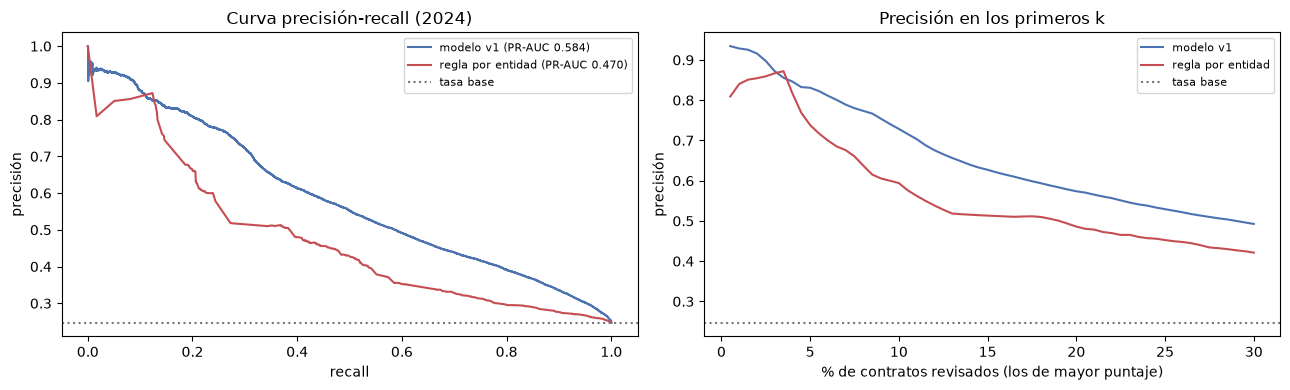

,p@1%,p@5%,p@10%,r@1%,r@5%,r@10%
modelo v1,0.928,0.831,0.729,0.038,0.168,0.295
regla por entidad,0.840,0.738,0.594,0.034,0.149,0.240


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (nombre, sc), color in zip(s.items(), ["#4C72B0", "#C44E52"]):
    p, r, _ = precision_recall_curve(y_te, sc)
    ax[0].plot(r, p, color=color, label=f"{nombre} (PR-AUC {E.metricas(y_te, sc)['pr_auc']:.3f})")
    fr = np.linspace(0.005, 0.3, 60)
    ax[1].plot(fr * 100, [E.metricas(y_te, sc, (f,))[f"p@{f:.0%}"] for f in fr], color=color, label=nombre)
for a in ax:
    a.axhline(y_te.mean(), color="#777", ls=":", label="tasa base")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precisión"); ax[0].set_title("Curva precisión-recall (2024)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("% de contratos revisados (los de mayor puntaje)"); ax[1].set_ylabel("precisión"); ax[1].set_title("Precisión en los primeros k"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame({k: {c: E.metricas(y_te, v)[c] for c in ["p@1%", "p@5%", "p@10%", "r@1%", "r@5%", "r@10%"]} for k, v in s.items()}).T

**Interpretación:** si la veeduría revisa el 5 % de mayor riesgo de 2024 (unos 4.400 contratos), con el modelo el 83 % termina con el plazo ampliado, frente al 74 % con la regla por entidad y al 25 % al azar. En el 10 % la diferencia es mayor (73 % frente a 59 %). Ojo: entre el 2 % y el 4 % las dos curvas casi se tocan; la ventaja del modelo en la parte más alta de la lista es pequeña y crece a partir del 5 %. El recall en esos cortes es bajo (17 % en el top 5 %) porque hay muchos más positivos que contratos revisables: la lista sirve para priorizar, no para encontrar todas las prórrogas.

## ROC-AUC dentro de entidad

In [21]:
r = E.roc_auc_intra_entidad(y_te, s["modelo v1"], ent_te, n_boot=200)
print(f"Modelo v1: por pares {r['pares']:.3f} [{r['pares_ic'][0]:.3f}, {r['pares_ic'][1]:.3f}] | "
      f"promedio por entidad {r['por_entidad']:.3f} [{r['por_entidad_ic'][0]:.3f}, {r['por_entidad_ic'][1]:.3f}]")
print(f"Calculado sobre {r['n_entidades']:,} entidades con ambas clases y {r['n_pares']:,} pares. La regla da 0,500 por construcción.")

Modelo v1: por pares 0.701 [0.604, 0.753] | promedio por entidad 0.703 [0.691, 0.716]
Calculado sobre 1,199 entidades con ambas clases y 11,953,889 pares. La regla da 0,500 por construcción.


**Interpretación:** dentro de una misma entidad, el modelo pone más arriba al contrato que se prorroga en el 70 % de los pares. La regla no puede ordenar nada ahí (todos los contratos de la entidad tienen el mismo puntaje). Es lo que necesita una oficina de control interno que solo vigila su propia entidad.

## Lo que muestra la app: nivel de riesgo y percentil

La app no muestra la probabilidad cruda. Muestra el percentil del puntaje frente a los contratos de 2024 y un nivel (bajo, medio, alto) con los umbrales del `.json` del modelo. Los umbrales son provisionales (percentiles 70 y 90 de 2024) y se acuerdan con Geronimo.

In [22]:
u = meta["umbrales_riesgo"]
sc = s["modelo v1"]
nivel = np.where(sc >= u["alto"], "alto", np.where(sc >= u["medio"], "medio", "bajo"))
t = pd.DataFrame({"y": y_te, "nivel": nivel}).groupby("nivel")["y"].agg(contratos="size", tasa_de_prorroga="mean").reindex(["bajo", "medio", "alto"])
t["% de los contratos"] = t["contratos"] / t["contratos"].sum() * 100
print(f"Umbrales: medio >= {u['medio']:.3f}, alto >= {u['alto']:.3f} ({u['metodo']})")
t

Umbrales: medio >= 0.334, alto >= 0.588 (percentiles 70 y 90 del puntaje en el test 2024 (maduros); provisional, se cuadra con Geronimo)


,contratos,tasa_de_prorroga,% de los contratos
nivel,,,
bajo,61661,0.142,69.999
medio,17618,0.375,20.000
alto,8809,0.729,10.000


**Interpretación:** en 2024 el nivel alto (10 % de los contratos) tiene 73 % de prórrogas, el medio 38 % y el bajo 14 %. Los niveles separan bien el riesgo y son fáciles de explicar a una persona sin formación técnica: "de cada 10 contratos en nivel alto, unos 7 terminaron con el plazo ampliado".

# 3.8 Despliegue

La interfaz para personas sin conocimientos técnicos vive en `app/` (arquitectura, flujo y capturas, con su URL pública).

**Flujo.** El usuario pega el número del contrato → la app consulta Contratos y Procesos en datos.gov.co → `src/features.py` construye **solo** las variables disponibles al firmar → el `Pipeline` del artefacto `models/modelo_prorroga_v1.joblib` puntúa → se muestra el nivel de riesgo (bajo/medio/alto) y el percentil (sección 3.7), con los factores que más explican el puntaje (SHAP, en lenguaje claro).

**Consistencia entrenamiento–uso.** La app reproduce exactamente el preprocesamiento (está dentro del `Pipeline` guardado) y descarta los campos de la lista de fuga aunque la API los devuelva actualizados.

---

# 3.9 Estrategia de reajuste

El monitoreo y la lógica campeón-retador viven en `src/monitoreo.py`: cómo se detecta la degradación, el criterio, la frecuencia y cómo se valida y promueve una nueva versión.

**Base medida en la sección 3.6 (deriva 2025).** El modelo congelado 2019-2023 baja de 0,584 a 0,550 de PR-AUC en 2025 pero le sigue ganando a la regla; reentrenar con 2019-2024 no mejora el PR-AUC (0,550 en los dos casos). Por eso el artefacto v1 se queda en 2019-2023 y el reentrenamiento se decide con el protocolo campeón-retador: se reentrena con datos nuevos, se compara el retador contra el campeón en una ventana temporal reciente con las mismas métricas de 3.7, y solo se promueve si mejora de forma clara. `src/modelo.py: construir_pipeline()` es el que usa ese monitoreo para reentrenar.

---